In [1]:
#Libraries Import & Data Loading
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset
df = pd.read_csv('car data.csv')
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [2]:
# Data Cleaning & Feature Engineering
print("Initial Shape:", df.shape)
print("\nMissing Values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())

# Drop duplicates if any
df.drop_duplicates(inplace=True)

# Feature Engineering: Extract Brand from Car_Name
df['Brand'] = df['Car_Name'].apply(lambda x: str(x).split(' ')[0])

# Feature Engineering: Calculate Car Age (Current year is 2026)
df['Car_Age'] = 2026 - df['Year']

# Drop original 'Car_Name' and 'Year' columns
df.drop(columns=['Car_Name', 'Year'], inplace=True)
df.head()

Initial Shape: (301, 9)

Missing Values:
 Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Duplicates: 2


C:\Users\USER\AppData\Local\Temp\ipykernel_9252\3850098024.py:7: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)
C:\Users\USER\AppData\Local\Temp\ipykernel_9252\3850098024.py:16: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['Car_Name', 'Year'], inplace=True)


,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Brand,Car_Age
0,3.35,5.59,27000,Petrol,Dealer,Manual,0,ritz,12
1,4.75,9.54,43000,Diesel,Dealer,Manual,0,sx4,13
2,7.25,9.85,6900,Petrol,Dealer,Manual,0,ciaz,9
3,2.85,4.15,5200,Petrol,Dealer,Manual,0,wagon,15
4,4.60,6.87,42450,Diesel,Dealer,Manual,0,swift,12


C:\Users\USER\AppData\Local\Temp\ipykernel_9252\4260963774.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Fuel_Type', y='Selling_Price', data=df, palette='Set2')


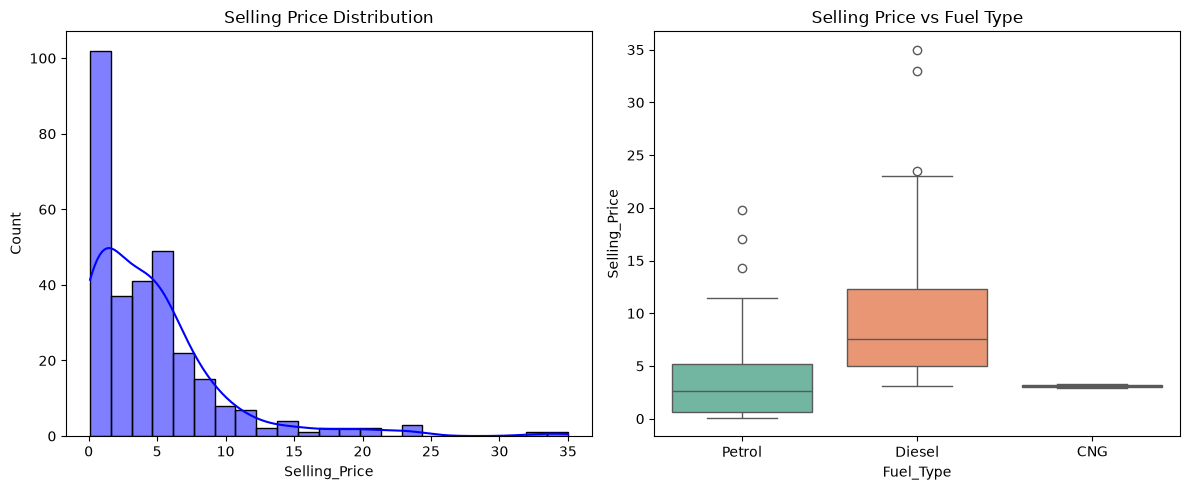

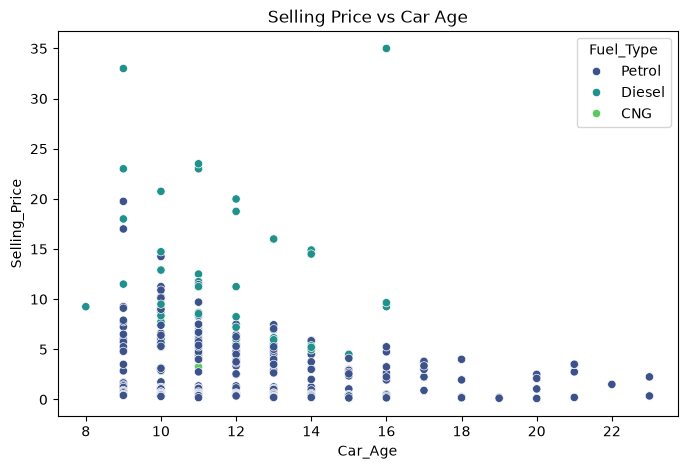

In [3]:
# Exploratory Data Analysis (EDA) & Visualizations
plt.figure(figsize=(12, 5))

# 1. Selling Price Distribution
plt.subplot(1, 2, 1)
sns.histplot(df['Selling_Price'], kde=True, color='blue')
plt.title('Selling Price Distribution')

# 2. Price vs Fuel Type Boxplot
plt.subplot(1, 2, 2)
sns.boxplot(x='Fuel_Type', y='Selling_Price', data=df, palette='Set2')
plt.title('Selling Price vs Fuel Type')

plt.tight_layout()
plt.show()

# 3. Price vs Car Age Scatter Plot
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Car_Age', y='Selling_Price', hue='Fuel_Type', data=df, palette='viridis')
plt.title('Selling Price vs Car Age')
plt.show()

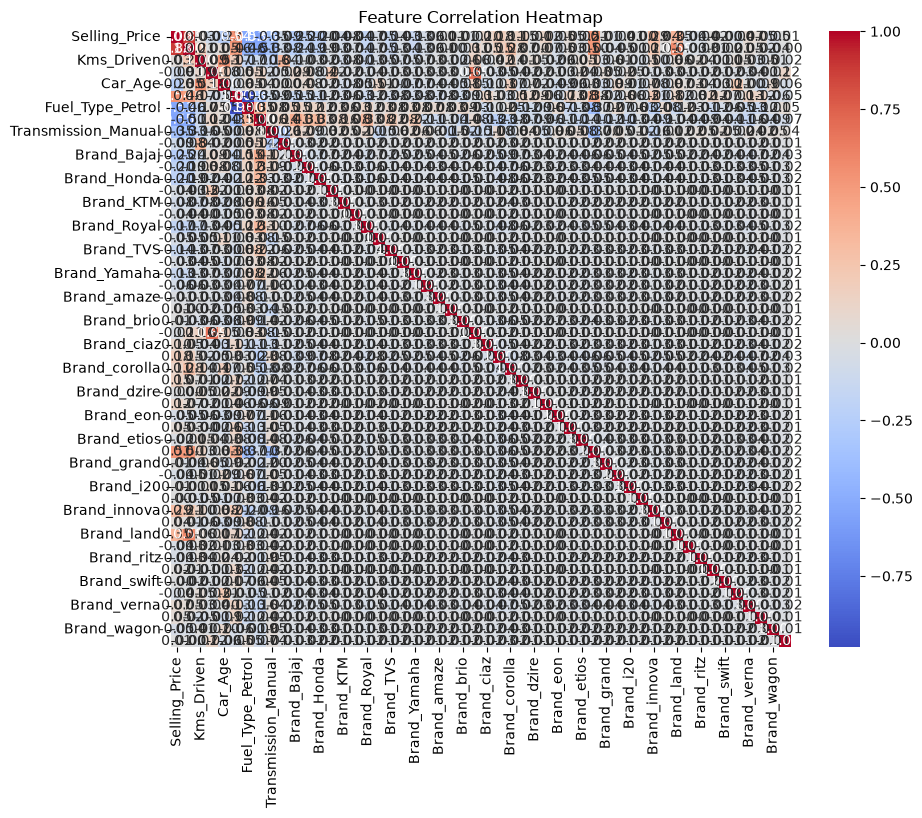

In [4]:
# Encoding Categorical Variables & Correlation Heatmap
# One-Hot Encoding for categorical features
df_encoded = pd.get_dummies(df, drop_first=True)

# Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df_encoded.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.show()

In [5]:
# Train/Test Split & Model Training
X = df_encoded.drop(columns=['Selling_Price'])
y = df_encoded['Selling_Price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Linear Regression Baseline
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

# 2. Random Forest Regressor
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# Evaluation Function
def evaluate_model(y_true, y_pred, model_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"--- {model_name} ---")
    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R² Score: {r2:.4f}\n")

evaluate_model(y_test, y_pred_lr, "Linear Regression")
evaluate_model(y_test, y_pred_rf, "Random Forest Regressor")

--- Linear Regression ---
MAE: 1.3835
RMSE: 2.5699
R² Score: 0.7438

--- Random Forest Regressor ---
MAE: 1.3748
RMSE: 3.3142
R² Score: 0.5738



C:\Users\USER\AppData\Local\Temp\ipykernel_9252\3343342865.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_imp_df.head(10), palette='magma')


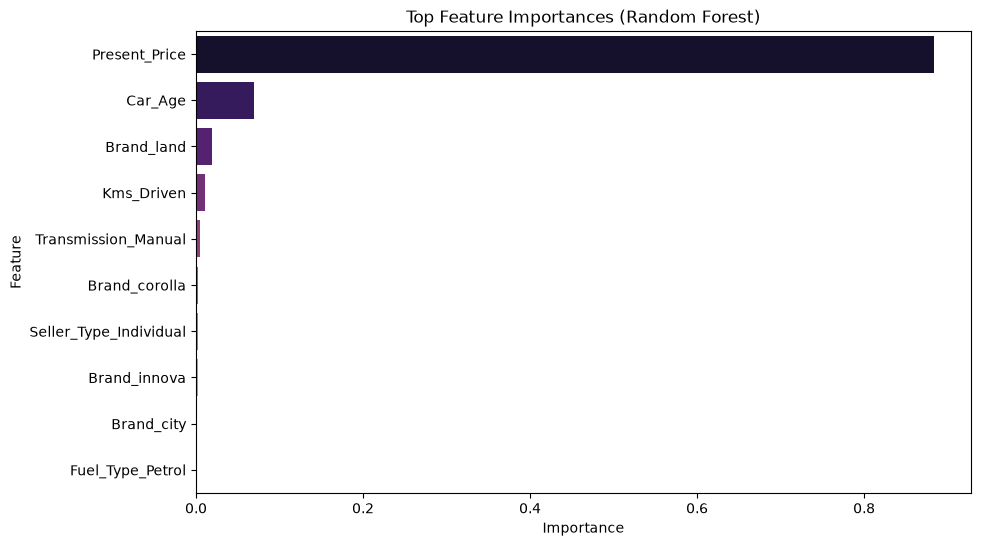

In [6]:
# Feature Importance for Random Forest
importances = rf.feature_importances_
features = X.columns

feature_imp_df = pd.DataFrame({'Feature': features, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df.head(10), palette='magma')
plt.title('Top Feature Importances (Random Forest)')
plt.show()